In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("startup_data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (50, 5)


,RD_Spend,Administration,Marketing_Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RD_Spend         50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing_Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.5 KB


In [4]:
df.describe()

,RD_Spend,Administration,Marketing_Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [5]:
df.isnull().sum()

RD_Spend           0
Administration     0
Marketing_Spend    0
State              0
Profit             0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['State'].value_counts()

State
New York      17
California    17
Florida       16
Name: count, dtype: int64

In [8]:
df.groupby('State')['Profit'].agg(['count', 'mean', 'sum']).round(2)

,count,mean,sum
State,,,
California,17,103905.18,1766387.98
Florida,16,118774.02,1900384.39
New York,17,113756.45,1933859.59


In [9]:
df[['RD_Spend', 'Profit']].corr()

,RD_Spend,Profit
RD_Spend,1.0000,0.9729
Profit,0.9729,1.0000


In [10]:
df[['Marketing_Spend', 'Profit']].corr()

,Marketing_Spend,Profit
Marketing_Spend,1.000000,0.747766
Profit,0.747766,1.000000


In [11]:
df[['Administration', 'Profit']].corr()

,Administration,Profit
Administration,1.000000,0.200717
Profit,0.200717,1.000000


In [12]:
df[['RD_Spend', 'Administration', 'Marketing_Spend', 'Profit']].corr().round(2)

,RD_Spend,Administration,Marketing_Spend,Profit
RD_Spend,1.00,0.24,0.72,0.97
Administration,0.24,1.00,-0.03,0.20
Marketing_Spend,0.72,-0.03,1.00,0.75
Profit,0.97,0.20,0.75,1.00


In [13]:
X = df[['RD_Spend', 'Administration', 'Marketing_Spend']]
y = df['Profit']

print("Input features (X):")
print(X.head())

print("\nTarget variable (y):")
print(y.head())

Input features (X):
    RD_Spend  Administration  Marketing_Spend
0  165349.20       136897.80        471784.10
1  162597.70       151377.59        443898.53
2  153441.51       101145.55        407934.54
3  144372.41       118671.85        383199.62
4  142107.34        91391.77        366168.42

Target variable (y):
0    192261.83
1    191792.06
2    191050.39
3    182901.99
4    166187.94
Name: Profit, dtype: float64


In [14]:
X = df[['RD_Spend', 'Administration', 'Marketing_Spend']]
y = df['Profit']

print("Input features (X):")
print(X.head())

print("\nTarget variable (y):")
print(y.head())

Input features (X):
    RD_Spend  Administration  Marketing_Spend
0  165349.20       136897.80        471784.10
1  162597.70       151377.59        443898.53
2  153441.51       101145.55        407934.54
3  144372.41       118671.85        383199.62
4  142107.34        91391.77        366168.42

Target variable (y):
0    192261.83
1    191792.06
2    191050.39
3    182901.99
4    166187.94
Name: Profit, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40, 3)
Testing data: (10, 3)


In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 6979.152252370399
Mean Squared Error: 80926321.22295156
R2 Score: 0.9000653083037321


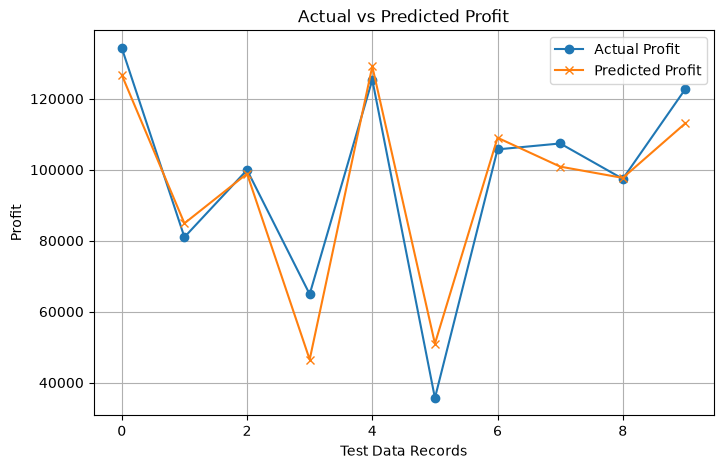

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(y_test.values, label='Actual Profit', marker='o')
plt.plot(y_pred, label='Predicted Profit', marker='x')

plt.title('Actual vs Predicted Profit')
plt.xlabel('Test Data Records')
plt.ylabel('Profit')
plt.legend()
plt.grid(True)
plt.show()

In [19]:
print("Model Intercept:", model.intercept_)

print("\nModel Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Model Intercept: 54071.87574599087

Model Coefficients:
RD_Spend : 0.8037792756297526
Administration : -0.06792917400149993
Marketing_Spend : 0.031241545897732773


In [20]:
new_startup = pd.DataFrame({
    'RD_Spend': [165349.20],
    'Administration': [136897.80],
    'Marketing_Spend': [471784.10]
})

predicted_profit = model.predict(new_startup)

print("Predicted Startup Profit:", round(predicted_profit[0], 2))

Predicted Startup Profit: 192416.05


In [21]:
comparison.to_csv("profit_prediction_results.csv", index=False)

print("Prediction results saved successfully!")

NameError: name 'comparison' is not defined

In [22]:
comparison = pd.DataFrame({
    'Actual Profit': y_test.values,
    'Predicted Profit': y_pred
})

comparison['Predicted Profit'] = comparison['Predicted Profit'].round(2)

comparison.to_csv("profit_prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


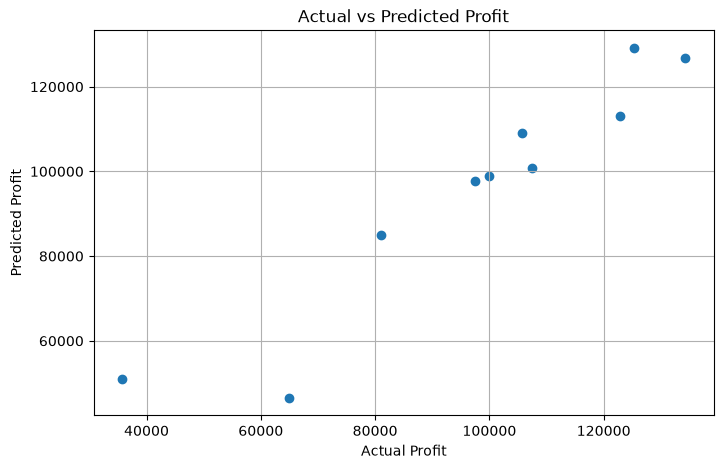

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Predicted Profit")
plt.grid(True)

plt.show()

In [24]:
results = pd.DataFrame({
    'Actual Profit': y_test.values,
    'Predicted Profit': y_pred.round(2)
})

results['Prediction Error'] = (
    results['Actual Profit'] - results['Predicted Profit']
).round(2)

results

,Actual Profit,Predicted Profit,Prediction Error
0,134307.35,126703.03,7604.32
1,81005.76,84894.75,-3888.99
2,99937.59,98893.42,1044.17
3,64926.08,46501.71,18424.37
4,125370.37,129128.40,-3758.03
5,35673.41,50992.69,-15319.28
6,105733.54,109016.55,-3283.01
7,107404.34,100878.46,6525.88
8,97427.84,97700.60,-272.76
9,122776.86,113106.15,9670.71


In [25]:
results.to_csv("final_profit_analysis.csv", index=False)

print("Final profit analysis saved successfully!")

Final profit analysis saved successfully!


In [26]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

importance['Absolute Coefficient'] = importance['Coefficient'].abs()

importance.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

,Feature,Coefficient,Absolute Coefficient
0,RD_Spend,0.803779,0.803779
1,Administration,-0.067929,0.067929
2,Marketing_Spend,0.031242,0.031242


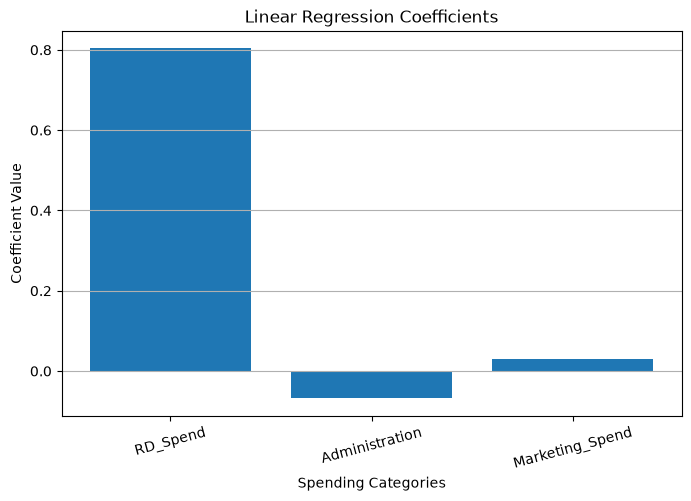

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(importance['Feature'], importance['Coefficient'])

plt.title('Linear Regression Coefficients')
plt.xlabel('Spending Categories')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=15)
plt.grid(axis='y')

plt.show()

In [28]:
print("========== STARTUP PROFIT ANALYSIS ==========")

print("Total Startups:", len(df))
print("Average Profit:", round(df['Profit'].mean(), 2))
print("Highest Profit:", round(df['Profit'].max(), 2))
print("Lowest Profit:", round(df['Profit'].min(), 2))

print("\n========== MODEL PERFORMANCE ==========")

print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

print("\n========== PROJECT COMPLETED ==========")

========== STARTUP PROFIT ANALYSIS ==========
Total Startups: 50
Average Profit: 112012.64
Highest Profit: 192261.83
Lowest Profit: 14681.4

========== MODEL PERFORMANCE ==========
MAE: 6979.15
R2 Score: 0.9001

========== PROJECT COMPLETED ==========


In [29]:
summary = f"""
STARTUP PROFIT ANALYSIS PROJECT

Total Startups: {len(df)}
Average Profit: {df['Profit'].mean():.2f}
Highest Profit: {df['Profit'].max():.2f}
Lowest Profit: {df['Profit'].min():.2f}

MODEL PERFORMANCE

Mean Absolute Error: {mean_absolute_error(y_test, y_pred):.2f}
R2 Score: {r2_score(y_test, y_pred):.4f}

The project used Multiple Linear Regression to predict startup profit
based on R&D, Administration, and Marketing spending.
"""

with open("project_summary.txt", "w") as file:
    file.write(summary)

print("Project summary saved successfully!")

Project summary saved successfully!
